
# Analyse comparative des solutions AutoML - PyCaret et AutoGluon

## Projet VolatiChainXplorerAI - Sprint 2

Ce notebook est consacré à l'analyse comparative des résultats expérimentaux obtenus avec **PyCaret** et **AutoGluon Tabular**, pour la prédiction de la volatilité du Bitcoin à 7 et 30 jours.

Les deux solutions ont été expérimentées sur les partitions chronologiques préalablement figées, selon un protocole commun définissant les données, les ressources de calcul, le budget d'entraînement et les métriques d'évaluation.

L'analyse porte sur :

- les performances prédictives : MAE, RMSE et R² ;
- les temps d'entraînement et d'inférence ;
- les ressources CPU et RAM ;
- les limites méthodologiques des expérimentations ;
- l'adéquation des solutions aux besoins de VolatiChainXplorerAI.

**Objectif :** comparer les résultats obtenus sur les partitions de test communes et identifier la solution AutoML la plus adaptée aux contraintes du projet.

Aucun nouvel entraînement n'est réalisé dans ce notebook. L'analyse repose exclusivement sur les résultats expérimentaux précédemment enregistrés.


In [3]:
import sys

import matplotlib
import numpy as np
import pandas as pd

print("Environnement :", sys.executable)
print("Pandas :", pd.__version__)
print("NumPy :", np.__version__)
print("Matplotlib :", matplotlib.__version__)

Environnement : d:\ProjectFolderDevAI_2025-2026\Certification BLOCS 2&3\Projet-VolatiChainXplorerAI\.venv\Scripts\python.exe
Pandas : 2.2.3
NumPy : 2.2.6
Matplotlib : 3.11.2


## 1. Charger les résultats expérimentaux

In [1]:
from pathlib import Path

project_root = Path().cwd().parent

results_dir = (
    project_root
    / "docs"
    / "benchmark"
    / "results_benchmark"
)

baseline_results_path = (
    results_dir
    / "baseline_test_results.csv"
)

pycaret_results_path = (
    results_dir
    / "pycaret_test_results.csv"
)

autogluon_results_path = (
    results_dir
    / "autogluon_test_results.csv"
)
print("Results directory:")
print(results_dir)
print("Baseline results path:")
print(baseline_results_path)
print("PyCaret results path:")
print(pycaret_results_path)
print("AutoGluon results path:")
print(autogluon_results_path)

Results directory:
d:\ProjectFolderDevAI_2025-2026\Certification BLOCS 2&3\Projet-VolatiChainXplorerAI\docs\benchmark\results_benchmark
Baseline results path:
d:\ProjectFolderDevAI_2025-2026\Certification BLOCS 2&3\Projet-VolatiChainXplorerAI\docs\benchmark\results_benchmark\baseline_test_results.csv
PyCaret results path:
d:\ProjectFolderDevAI_2025-2026\Certification BLOCS 2&3\Projet-VolatiChainXplorerAI\docs\benchmark\results_benchmark\pycaret_test_results.csv
AutoGluon results path:
d:\ProjectFolderDevAI_2025-2026\Certification BLOCS 2&3\Projet-VolatiChainXplorerAI\docs\benchmark\results_benchmark\autogluon_test_results.csv


In [7]:
# Charger les resultats

pycaret_results = pd.read_csv(
    pycaret_results_path
)

baseline_results = pd.read_csv(
    baseline_results_path
)

autogluon_results = pd.read_csv(
    autogluon_results_path
)

print("PyCaret results:")
display(pycaret_results)
print("Dimension de PyCaret results:", pycaret_results.shape)
print("\nBaseline results:")
display(baseline_results)
print("Dimension de Baseline results:", baseline_results.shape)
print("\nAutoGluon results:")
display(autogluon_results)
print("Dimension de AutoGluon results:", autogluon_results.shape)

PyCaret results:


,tool,horizon,model,MAE,RMSE,R2,inference_time_seconds,training_time_seconds,peak_cpu_percent,peak_ram_used_mb
0,PyCaret,7d,HuberRegressor,0.008293,0.012347,-0.253132,0.444908,41.14,100.0,15276.83
1,PyCaret,7d,LassoLars,0.018931,0.020405,-2.422448,0.380458,41.14,100.0,15276.83
2,PyCaret,7d,DummyRegressor,0.018931,0.020405,-2.422448,0.156920,41.14,100.0,15276.83
3,PyCaret,30d,Lasso,0.019914,0.021169,-7.029626,0.386425,36.94,100.0,15159.97
4,PyCaret,30d,LassoLars,0.019914,0.021169,-7.029626,0.463464,36.94,100.0,15159.97
5,PyCaret,30d,DummyRegressor,0.019914,0.021169,-7.029626,0.179289,36.94,100.0,15159.97


Dimension de PyCaret results: (6, 10)

Baseline results:


,tool,horizon,model,MAE,MSE,RMSE,R2
0,Baseline,7d,VolatilityPersistence,0.009354,0.000180,0.013431,-0.482664
1,Baseline,30d,VolatilityPersistence,0.006931,0.000087,0.009353,-0.567560


Dimension de Baseline results: (2, 7)

AutoGluon results:


,tool,horizon,model,MAE,RMSE,R2,inference_time_seconds,training_time_seconds,peak_cpu_percent,peak_ram_used_mb
0,AutoGluon,7d,WeightedEnsemble_L2,0.008544,0.011058,-0.005152,0.159108,89.37,100.0,15156.62
1,AutoGluon,7d,NeuralNetTorch,0.007820,0.011156,-0.023035,0.254139,89.37,100.0,15156.62
2,AutoGluon,7d,LightGBMXT,0.013604,0.015526,-0.981313,0.018693,89.37,100.0,15156.62
3,AutoGluon,30d,WeightedEnsemble_L2,0.006251,0.007711,-0.065475,0.078105,44.10,100.0,15354.15
4,AutoGluon,30d,NeuralNetTorch,0.005722,0.008374,-0.256412,0.097500,44.10,100.0,15354.15
5,AutoGluon,30d,CatBoost,0.019382,0.020651,-6.642020,0.021151,44.10,100.0,15354.15


Dimension de AutoGluon results: (6, 10)


## 2. Vérifier la cohérence des données

In [9]:
# Vérifier les colonnes
print("Colonnes identiques :",
      pycaret_results.columns.equals(autogluon_results.columns))

# Vérifier les valeurs manquantes
print("\nValeurs manquantes :")
print("PyCaret :", pycaret_results.isna().sum().sum())
print("AutoGluon :", autogluon_results.isna().sum().sum())
print("Baseline :", baseline_results.isna().sum().sum())

# Vérifier la répartition par horizon
print("\nRépartition par horizon :")
print("PyCaret :")
print(pycaret_results["horizon"].value_counts())

print("\nAutoGluon :")
print(autogluon_results["horizon"].value_counts())

print("\nBaseline :")
print(baseline_results["horizon"].value_counts())

Colonnes identiques : True

Valeurs manquantes :
PyCaret : 0
AutoGluon : 0
Baseline : 0

Répartition par horizon :
PyCaret :
horizon
7d     3
30d    3
Name: count, dtype: int64

AutoGluon :
horizon
7d     3
30d    3
Name: count, dtype: int64

Baseline :
horizon
7d     1
30d    1
Name: count, dtype: int64


## 3. Fusionner des résultats baseline, PyCaret et AutoGluon

In [11]:
# Fusionner les résultats des deux outils
benchmark_results = pd.concat(
    [pycaret_results, autogluon_results],
    ignore_index=True
)

# Trier les résultats par horizon, puis par outil
benchmark_results["horizon"] = pd.Categorical(
    benchmark_results["horizon"],
    categories=["7d", "30d"],
    ordered=True
)

benchmark_results = benchmark_results.sort_values(
    by=["horizon", "tool", "RMSE"]
).reset_index(drop=True)

# Vérifier le tableau fusionné
print("Dimensions :", benchmark_results.shape)

display(benchmark_results)

Dimensions : (12, 10)


,tool,horizon,model,MAE,RMSE,R2,inference_time_seconds,training_time_seconds,peak_cpu_percent,peak_ram_used_mb
0,AutoGluon,7d,WeightedEnsemble_L2,0.008544,0.011058,-0.005152,0.159108,89.37,100.0,15156.62
1,AutoGluon,7d,NeuralNetTorch,0.007820,0.011156,-0.023035,0.254139,89.37,100.0,15156.62
2,AutoGluon,7d,LightGBMXT,0.013604,0.015526,-0.981313,0.018693,89.37,100.0,15156.62
3,PyCaret,7d,HuberRegressor,0.008293,0.012347,-0.253132,0.444908,41.14,100.0,15276.83
4,PyCaret,7d,LassoLars,0.018931,0.020405,-2.422448,0.380458,41.14,100.0,15276.83
5,PyCaret,7d,DummyRegressor,0.018931,0.020405,-2.422448,0.156920,41.14,100.0,15276.83
6,AutoGluon,30d,WeightedEnsemble_L2,0.006251,0.007711,-0.065475,0.078105,44.10,100.0,15354.15
7,AutoGluon,30d,NeuralNetTorch,0.005722,0.008374,-0.256412,0.097500,44.10,100.0,15354.15
8,AutoGluon,30d,CatBoost,0.019382,0.020651,-6.642020,0.021151,44.10,100.0,15354.15
9,PyCaret,30d,Lasso,0.019914,0.021169,-7.029626,0.386425,36.94,100.0,15159.97


## 4. Intégrer la baseline au tableau comparatif

In [12]:
# Fusion des résultats AutoML et de la baseline
comparison_all = pd.concat(
    [benchmark_results, baseline_results],
    ignore_index=True
)

# Sélection des métriques communes
comparison_metrics = comparison_all[
    ["tool", "horizon", "model", "MAE", "RMSE", "R2"]
].copy()

# Tri par horizon et RMSE croissante
comparison_metrics["horizon"] = pd.Categorical(
    comparison_metrics["horizon"],
    categories=["7d", "30d"],
    ordered=True
)

comparison_metrics = comparison_metrics.sort_values(
    ["horizon", "RMSE"]
).reset_index(drop=True)

print("Dimensions :", comparison_metrics.shape)
display(comparison_metrics.round(6))

Dimensions : (14, 6)


,tool,horizon,model,MAE,RMSE,R2
0,AutoGluon,7d,WeightedEnsemble_L2,0.008544,0.011058,-0.005152
1,AutoGluon,7d,NeuralNetTorch,0.007820,0.011156,-0.023035
2,PyCaret,7d,HuberRegressor,0.008293,0.012347,-0.253132
3,Baseline,7d,VolatilityPersistence,0.009354,0.013431,-0.482664
4,AutoGluon,7d,LightGBMXT,0.013604,0.015526,-0.981313
5,PyCaret,7d,LassoLars,0.018931,0.020405,-2.422448
6,PyCaret,7d,DummyRegressor,0.018931,0.020405,-2.422448
7,AutoGluon,30d,WeightedEnsemble_L2,0.006251,0.007711,-0.065475
8,AutoGluon,30d,NeuralNetTorch,0.005722,0.008374,-0.256412
9,Baseline,30d,VolatilityPersistence,0.006931,0.009353,-0.567560


## 5. Comparer la MAE et la RMSE à 7 et 30 jours

Ce que nous allons examiner :
- MAE : l'erreur absolue moyenne des prédictions.
- RMSE : l'erreur quadratique moyenne, qui pénalise davantage les erreurs importantes.
- R² : la performance du modèle par rapport à une prédiction constante égale à la moyenne des valeurs du jeu de test.

Pour la **MAE** et la **RMSE**, plus la valeur est faible, **meilleure est la performance**.

### A. Comparaison à 7 jours

In [13]:
# Sélectionner les résultats à 7 jours
results_7d = comparison_metrics[
    comparison_metrics["horizon"] == "7d"
].copy()

# Afficher uniquement les indicateurs prédictifs
comparison_7d = results_7d[
    ["tool", "model", "MAE", "RMSE", "R2"]
].sort_values(by="RMSE")

display(comparison_7d.round(6))

,tool,model,MAE,RMSE,R2
0,AutoGluon,WeightedEnsemble_L2,0.008544,0.011058,-0.005152
1,AutoGluon,NeuralNetTorch,0.007820,0.011156,-0.023035
2,PyCaret,HuberRegressor,0.008293,0.012347,-0.253132
3,Baseline,VolatilityPersistence,0.009354,0.013431,-0.482664
4,AutoGluon,LightGBMXT,0.013604,0.015526,-0.981313
5,PyCaret,LassoLars,0.018931,0.020405,-2.422448
6,PyCaret,DummyRegressor,0.018931,0.020405,-2.422448


### B. Comparaison à 30 jours

In [14]:
# Sélectionner les résultats à 7 jours
results_30d = comparison_metrics[
    comparison_metrics["horizon"] == "30d"
].copy()

# Afficher uniquement les indicateurs prédictifs
comparison_30d = results_30d[
    ["tool", "model", "MAE", "RMSE", "R2"]
].sort_values(by="RMSE")

display(comparison_30d.round(6))

,tool,model,MAE,RMSE,R2
7,AutoGluon,WeightedEnsemble_L2,0.006251,0.007711,-0.065475
8,AutoGluon,NeuralNetTorch,0.005722,0.008374,-0.256412
9,Baseline,VolatilityPersistence,0.006931,0.009353,-0.567560
10,AutoGluon,CatBoost,0.019382,0.020651,-6.642020
11,PyCaret,Lasso,0.019914,0.021169,-7.029626
12,PyCaret,LassoLars,0.019914,0.021169,-7.029626
13,PyCaret,DummyRegressor,0.019914,0.021169,-7.029626


## 6. Calculer les gains de performance par rapport à la baseline.

In [15]:
# Extraire la RMSE de référence pour chaque horizon
baseline_rmse = (
    comparison_metrics[
        comparison_metrics["tool"] == "Baseline"
    ]
    .set_index("horizon")["RMSE"]
)

# Copier le tableau comparatif
comparison_gain = comparison_metrics.copy()

# Associer la RMSE de la baseline à chaque ligne
comparison_gain["baseline_RMSE"] = (
    comparison_gain["horizon"].map(baseline_rmse)
    .astype(float)
)

# Calculer le gain relatif en pourcentage
comparison_gain["RMSE_gain_percent"] = (
    (comparison_gain["baseline_RMSE"] - comparison_gain["RMSE"])
    / comparison_gain["baseline_RMSE"]
) * 100

display(
    comparison_gain[
        ["tool", "horizon", "model", "RMSE", "RMSE_gain_percent"]
    ].round(2)
)

,tool,horizon,model,RMSE,RMSE_gain_percent
0,AutoGluon,7d,WeightedEnsemble_L2,0.01,17.66
1,AutoGluon,7d,NeuralNetTorch,0.01,16.93
2,PyCaret,7d,HuberRegressor,0.01,8.07
3,Baseline,7d,VolatilityPersistence,0.01,0.00
4,AutoGluon,7d,LightGBMXT,0.02,-15.60
5,PyCaret,7d,LassoLars,0.02,-51.93
6,PyCaret,7d,DummyRegressor,0.02,-51.93
7,AutoGluon,30d,WeightedEnsemble_L2,0.01,17.56
8,AutoGluon,30d,NeuralNetTorch,0.01,10.47
9,Baseline,30d,VolatilityPersistence,0.01,0.00


## 7. Visualisation comparative avec la baseline concernant les RMSE

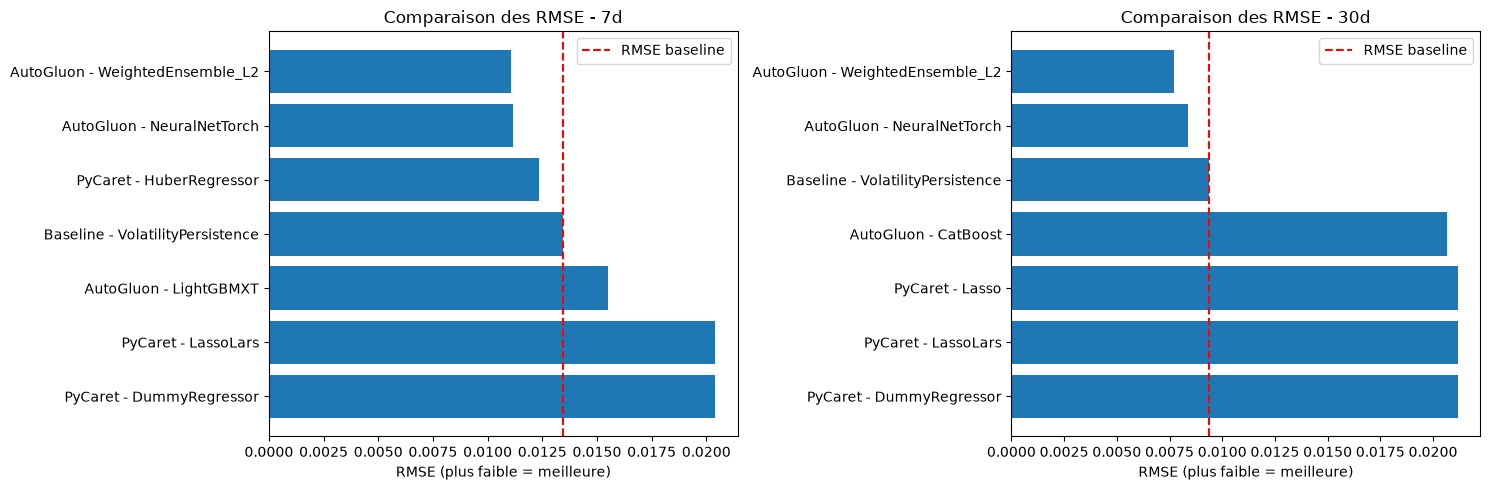

In [17]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, horizon in zip(axes, ["7d", "30d"]):

    subset = comparison_metrics[
        comparison_metrics["horizon"] == horizon
    ].sort_values("RMSE")

    labels = subset["tool"] + " - " + subset["model"]

    ax.barh(labels, subset["RMSE"])
    ax.invert_yaxis()

    # Ligne verticale représentant la baseline
    reference = subset.loc[
        subset["tool"] == "Baseline", "RMSE"
    ].iloc[0]

    ax.axvline(
        reference,
        color="red",
        linestyle="--",
        linewidth=1.5,
        label="RMSE baseline"
    )

    ax.set_title(f"Comparaison des RMSE - {horizon}")
    ax.set_xlabel("RMSE (plus faible = meilleure)")
    ax.legend()

plt.tight_layout()
plt.show()

### Interprétation des performances comparées à la baseline

L'analyse graphique des RMSE met en évidence une amélioration des performances prédictives de certains modèles AutoML par rapport à la baseline de persistance de la volatilité historique.

À **7 jours**, les modèles `WeightedEnsemble_L2` et `NeuralNetTorch` d'AutoGluon, ainsi que `HuberRegressor` de PyCaret, présentent une RMSE inférieure à celle de la baseline.

À **30 jours**, seuls `WeightedEnsemble_L2` et `NeuralNetTorch` maintiennent cet avantage.

Le modèle `WeightedEnsemble_L2` se distingue sur les deux horizons, avec une réduction relative de la RMSE de **17,66 % à 7 jours** et de **17,56 % à 30 jours**.

Ces résultats indiquent qu'AutoGluon offre les meilleures performances prédictives relatives parmi les solutions évaluées. Toutefois, les coefficients de détermination négatifs invitent à nuancer cette observation : aucun modèle ne surpasse la référence constante utilisée dans le calcul du R² sur les jeux de test.

**Conclusion intermédiaire :** AutoGluon apparaît comme le candidat le plus prometteur, mais sa pertinence opérationnelle devra être appréciée au regard des autres critères du benchmark et des limites observées.

## 8. Comparer les ressources

In [14]:
# Extraire les mesures globales par expérimentation
resources_comparison = benchmark_results[
    [
        "tool",
        "horizon",
        "training_time_seconds",
        "peak_cpu_percent",
        "peak_ram_used_mb"
    ]
].drop_duplicates(
    subset=["tool", "horizon"]
)

# Organiser les résultats
resources_comparison = resources_comparison.sort_values(
    by=["horizon", "tool"]
).reset_index(drop=True)

display(resources_comparison.round(2))

,tool,horizon,training_time_seconds,peak_cpu_percent,peak_ram_used_mb
0,AutoGluon,7d,89.37,100.0,15156.62
1,PyCaret,7d,41.14,100.0,15276.83
2,AutoGluon,30d,44.10,100.0,15354.15
3,PyCaret,30d,36.94,100.0,15159.97


## 9. Comparer les temps d'inférence

In [15]:
# Comparer les temps d'inférence des modèles
inference_comparison = benchmark_results[
    [
        "tool",
        "horizon",
        "model",
        "inference_time_seconds"
    ]
].sort_values(
    by=["horizon", "inference_time_seconds"]
).reset_index(drop=True)

display(inference_comparison.round(4))

,tool,horizon,model,inference_time_seconds
0,AutoGluon,7d,LightGBMXT,0.0187
1,PyCaret,7d,DummyRegressor,0.1569
2,AutoGluon,7d,WeightedEnsemble_L2,0.1591
3,AutoGluon,7d,NeuralNetTorch,0.2541
4,PyCaret,7d,LassoLars,0.3805
5,PyCaret,7d,HuberRegressor,0.4449
6,AutoGluon,30d,CatBoost,0.0212
7,AutoGluon,30d,WeightedEnsemble_L2,0.0781
8,AutoGluon,30d,NeuralNetTorch,0.0975
9,PyCaret,30d,DummyRegressor,0.1793


## 10. Synthèse multicritère et conclusion du benchmark AutoML

### 10.1. Synthèse des résultats

L'analyse comparative des solutions **PyCaret** et **AutoGluon Tabular**, complétée par une baseline de persistance de la volatilité historique, permet d'évaluer les performances prédictives et les contraintes techniques des approches étudiées sur deux horizons : 7 et 30 jours.

| Critère d'évaluation | Solution avantagée | Observation |
|---|---|---|
| MAE | AutoGluon | Erreurs absolues moyennes minimales aux deux horizons |
| RMSE | AutoGluon | `WeightedEnsemble_L2` présente les meilleurs résultats |
| Gain de RMSE par rapport à la baseline | AutoGluon | 17,66 % à 7 jours et 17,56 % à 30 jours |
| R² | AutoGluon | Valeurs les plus élevées, mais toujours négatives |
| Temps d'entraînement | PyCaret | Durées expérimentales globales plus courtes |
| Temps d'inférence | AutoGluon | Temps les plus courts observés sur les lots de test |
| Ressources CPU/RAM | Non départagé | Mesures globales insuffisantes pour évaluer précisément la consommation propre à chaque outil |

### 10.2. Analyse des performances prédictives

Le modèle `WeightedEnsemble_L2` d'AutoGluon obtient les meilleures performances en RMSE sur les deux horizons.

Par rapport à la baseline de persistance, il réduit la RMSE de :

- **17,66 % à 7 jours**, avec une RMSE de 0,011058 contre 0,013431 pour la baseline.
- **17,56 % à 30 jours**, avec une RMSE de 0,007711 contre 0,009353 pour la baseline.

PyCaret présente également une amélioration à 7 jours avec `HuberRegressor`, mais aucun de ses modèles évalués ne surpasse la baseline à 30 jours.

Ces observations mettent en évidence un **avantage prédictif mesurable d'AutoGluon par rapport à la baseline métier**, sur les jeux de test utilisés.

Néanmoins, les coefficients de détermination restent négatifs pour l'ensemble des modèles, ce qui limite les conclusions concernant leur capacité prédictive globale.

### 10.3. Analyse des performances techniques

PyCaret se distingue par des durées d'expérimentation plus courtes.

AutoGluon présente cependant des temps d'inférence compétitifs, notamment avec `WeightedEnsemble_L2`, dont les prédictions sur les lots de test de 590 observations nécessitent environ 0,159 seconde à 7 jours et 0,078 seconde à 30 jours.

Concernant les ressources CPU et RAM, les mesures réalisées reflètent l'utilisation globale du système et ne permettent pas d'établir une comparaison précise de l'efficacité matérielle de chaque outil.

Par ailleurs, les stratégies de validation interne des deux solutions diffèrent, ce qui impose de nuancer la comparaison de leurs durées expérimentales.

### 10.4. Conclusion et orientation technologique

Au regard des résultats obtenus, **AutoGluon Tabular est retenu comme solution AutoML privilégiée à l'issue du benchmark comparatif**, notamment grâce aux performances de son modèle `WeightedEnsemble_L2` sur les horizons de 7 et 30 jours.

Cette sélection constitue une **orientation technologique**, et non une validation définitive du modèle pour une utilisation opérationnelle.

En effet, malgré une amélioration de la RMSE par rapport à la baseline de persistance, les coefficients R² négatifs révèlent des limites prédictives qui devront être examinées avant toute mise en production.

La poursuite du projet VolatiChainXplorerAI devra donc porter sur la validation de la robustesse du modèle, l'analyse de ses erreurs et l'adéquation de ses performances aux besoins fonctionnels de l'application.

**Ainsi, le benchmark permet de privilégier AutoGluon comme solution technologique, tout en maintenant une distinction essentielle entre la sélection d'un outil AutoML et la validation opérationnelle du modèle prédictif.**

### 10.5. Comparaison des coûts des solutions AutoML

#### Tableau de comparaison des coûts - PyCaret vs AutoGluon Tabular

| Critère | PyCaret | AutoGluon Tabular |
|---|---|---|
| Acquisition du logiciel | Gratuit | Gratuit |
| Infrastructure du POC | PC local, CPU | Même PC local, CPU |
| Services cloud payants | Aucun utilisé | Aucun utilisé |
| Temps d'expérimentation - 7 jours | 41,14 s | 89,37 s |
| Temps d'expérimentation - 30 jours | 36,94 s | 44,10 s |
| Dépendances et installation | Environnement Python dédié | Environnement Python dédié ; difficulté de chemin Windows résolue (`WinError 206`) |
| Contraintes techniques bloquantes | Aucune constatée | Aucune constatée |
| Maintenance | Coût à estimer | Coût à estimer |
| Hébergement futur | Non chiffré | Non chiffré |


L'évaluation économique des solutions PyCaret et AutoGluon Tabular repose sur les conditions réelles des expérimentations effectuées dans le cadre du projet VolatiChainXplorerAI.

Les deux solutions ont été exécutées localement, sur une infrastructure CPU existante, sans recours à des services cloud facturés à l'usage.

**Coûts directs :** aucun coût d'acquisition logicielle ni de service cloud n'a été engagé pendant les expérimentations.

**Coûts de calcul :** PyCaret présente des durées expérimentales globales inférieures à celles d'AutoGluon sur les deux horizons. Toutefois, les mesures disponibles ne permettent pas de traduire ces durées en coûts énergétiques ou financiers précis.

**Coûts d'installation et de maintenance :** les deux solutions nécessitent des environnements Python spécifiques. L'installation d'AutoGluon a rencontré des contraintes de compatibilité et de chemins Windows, résolues par la création d'un environnement indépendant. Ces contraintes devront être prises en compte lors de l'industrialisation.

**Coûts de déploiement :** non évalués à ce stade. Ils dépendront de l'infrastructure retenue, de la mémoire nécessaire au chargement des modèles, de la fréquence des prédictions et des besoins de maintenance.

#### Conclusion

PyCaret bénéficie d'un avantage en matière de durée d'expérimentation dans le contexte étudié.

Cependant, cet avantage ne suffit pas à établir un coût total de possession inférieur, en l'absence de mesures financières d'exploitation.

**AutoGluon demeure la solution privilégiée**, compte tenu de ses performances prédictives supérieures, sous réserve de maîtriser ses dépendances et de confirmer sa viabilité économique et technique lors de l'intégration applicative.